In [1]:

import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))



/kaggle/input/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/Mall_Customers.csv


In [2]:

import glob
import pandas as pd

files = glob.glob("/kaggle/input/**/*.csv", recursive=True)

if files:
    print("Found dataset:", files[0])
    df = pd.read_csv(files[0])
    print("Dataset shape:", df.shape)
    display(df.head())
else:
    print("No CSV found. Click Add Input and attach the Mall Customers dataset.")


Found dataset: /kaggle/input/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/Mall_Customers.csv
Dataset shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())


Dataset shape: (200, 5)

Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [4]:

from sklearn.preprocessing import StandardScaler


X = df[["Annual Income (k$)", "Spending Score (1-100)"]]


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data prepared for DBSCAN!")
print("Number of samples:", X_scaled.shape[0])


Data prepared for DBSCAN!
Number of samples: 200


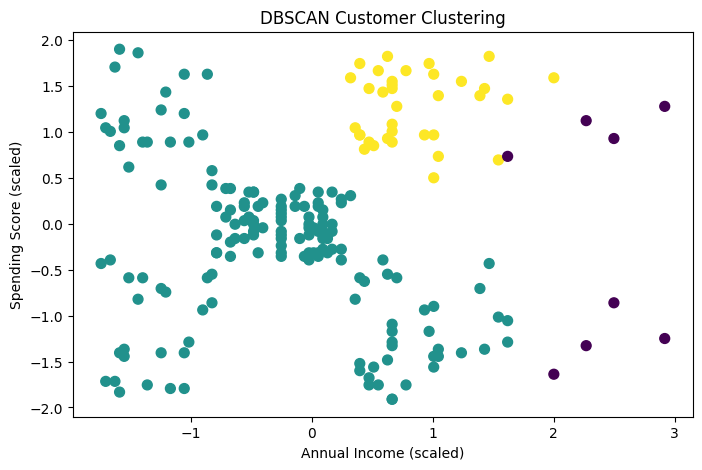

Number of clusters: 2
Noise points: 8


In [5]:

from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt

dbscan = DBSCAN(eps=0.5, min_samples=5)
labels = dbscan.fit_predict(X_scaled)

df["Cluster"] = labels

plt.figure(figsize=(8, 5))
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels,
    cmap="viridis",
    s=50
)
plt.xlabel("Annual Income (scaled)")
plt.ylabel("Spending Score (scaled)")
plt.title("DBSCAN Customer Clustering")
plt.show()

print("Number of clusters:", len(set(labels)) - (1 if -1 in labels else 0))
print("Noise points:", list(labels).count(-1))


In [6]:

from sklearn.cluster import DBSCAN
import numpy as np

for eps in [0.3, 0.4, 0.5, 0.6, 0.7]:
    labels = DBSCAN(
        eps=eps,
        min_samples=5
    ).fit_predict(X_scaled)

    clusters = len(set(labels) - {-1})
    noise = np.sum(labels == -1)

    print(
        f"eps={eps:.1f} | "
        f"Clusters={clusters} | "
        f"Noise points={noise}"
    )

 

eps=0.3 | Clusters=7 | Noise points=35
eps=0.4 | Clusters=4 | Noise points=15
eps=0.5 | Clusters=2 | Noise points=8
eps=0.6 | Clusters=1 | Noise points=5
eps=0.7 | Clusters=1 | Noise points=0
